### The inverse travelling wave

HSG 22.09

In [89]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt 
from Code.SpectralMethods.old.spectralNewton import solve_with_continuation

In [91]:
# -- Set-up --
N = 2**8
L = 8*np.pi
x = np.linspace(-L/2, L/2, N, endpoint=False)
k = 2*np.pi*np.fft.fftfreq(N, d = L/N)

# -- Soliton Travelling
def soliton_profile(x,c,x0=0.0):
    return (c/2)/np.cosh(np.sqrt(c)/2 * (x-x0))**2

In [92]:
c_values = np.array([0.5 , 1.0 , 1.5, 2.0 , 2.5])
n_samples = len(c_values)

phi_hat_list = []
nl_hat_list = []
dHdt_hat_list = []

for c in c_values:
    H = soliton_profile(x,c)
    H_hat = np.fft.fft(H)
    H2_hat = np.fft.fft(H**2)
    dHdt_hat = -1j*k*c*H_hat

    phi_hat_list.append(H_hat)
    nl_hat_list.append(H2_hat)
    dHdt_hat_list.append(dHdt_hat)

phi_hat =   np.stack(phi_hat_list,   axis = 1)
nl_hat =    np.stack(nl_hat_list,    axis = 1)
dHdt_hat =  np.stack(dHdt_hat_list,  axis = 1)

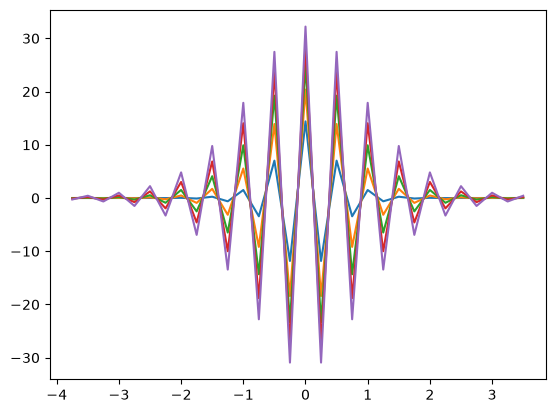

In [102]:
order = np.argsort(k)
k_sorted = k[order]
phi_hat_sorted = phi_hat[order]

i_ = 15
plt.plot(k_sorted[N//2 - i_:(N//2) + i_],phi_hat_sorted.real[N//2 - i_:(N//2) + i_])
plt.show()

In [94]:
A = np.stack([phi_hat, nl_hat], axis= 1)
A_pinv = np.linalg.pinv(A)
X = np.einsum('fs,fsc->fc', dHdt_hat,A_pinv)

ell = X[:,0]
n   = X[:,1]

In [95]:
ell_sorted = ell[order]
n_sorted = n[order]

In [100]:
# LSM on the "valid area" 
idx_ = 15
k_lsm = k_sorted[N//2 - idx_:(N//2) + idx_]
mk_lsm_ = ell_sorted[N//2 - idx_:(N//2) + idx_]
A = np.column_stack([np.ones_like(k_lsm), k_lsm , k_lsm**2, k_lsm**3, k_lsm**4])
x,residual, rank , s = np.linalg.lstsq(A,mk_lsm_.imag, rcond=None)

print(x)

[ 3.81488234e-03  5.02724616e-03 -3.84077521e-03  9.99054873e-01
  4.14285865e-04]


In [101]:
# LSM on the "valid area" 
k_lsm = k_sorted[N//2 - idx_:(N//2) + idx_]
mk_lsm_ = n_sorted[N//2 - idx_:(N//2) + idx_]
A = np.column_stack([np.ones_like(k_lsm), k_lsm , k_lsm**2, k_lsm**3, k_lsm**4])
x,residual, rank , s = np.linalg.lstsq(A,mk_lsm_.imag, rcond=None)

print(x)

[-6.71802754e-04 -3.00093709e+00  6.76362501e-04  1.81091325e-04
 -7.29559552e-05]
